Total null values: 0
?: 0, Missing: 0, Ellipsis: 0, N/A: 0
Beans classes remaining of 7: 7


<Axes: >

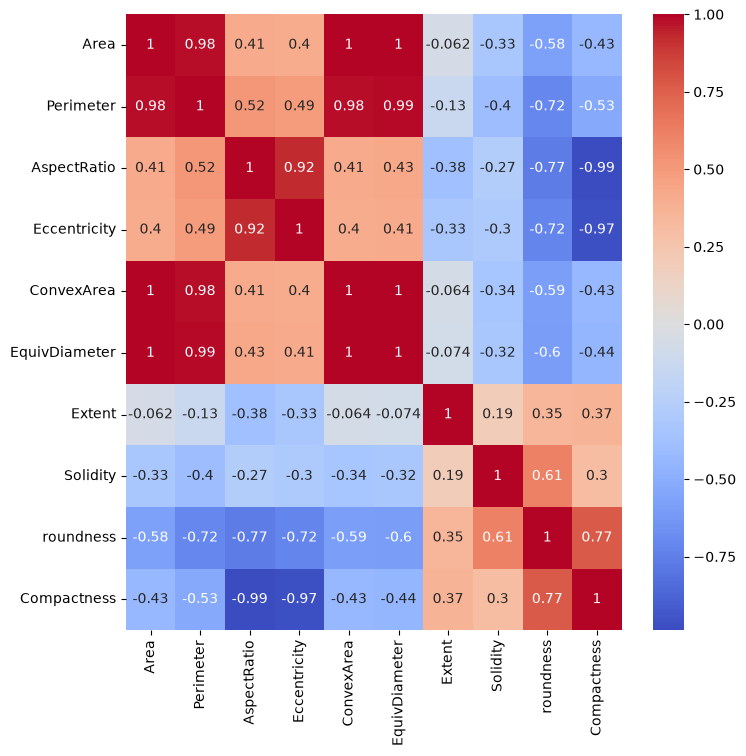

In [1]:
"""
This is the code for assignment 11. It uses the
dry bean dataset and performs k-means and
hierarchical clustering.
"""

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import cdist


beans_df = pd.read_csv("dry_bean_dataset.csv")

# I noticed this column's name was misspelled when
# compared to the website descriptions.
beans_df = beans_df.rename(columns={"AspectRation": "AspectRatio"})

# Since this dataset has a lot of columns, there are
# some I want to drop first because I know I won't be
# using them. This should make the other steps go slightly
# quicker due to having less data to process.

def drop_col (df: pd.DataFrame, col: str):
    """
    This function will drop a column from a dataframe.
    
    Input: beans_df dataframe (df) and the name of the column to drop
    as a string (col).
    
    Returns: DataFrame with specified column dropped.
    """

    dropped = df.drop(columns=col)

    return dropped

# Dropping these because they're multi-
# collinear with AspectRatio.
beans_df = drop_col(beans_df, "MajorAxisLength")
beans_df = drop_col(beans_df, "MinorAxisLength")
# Dropping these 4 because neither the
# website nor the readme explains what
# they represent.
beans_df = drop_col(beans_df, "ShapeFactor1")
beans_df = drop_col(beans_df, "ShapeFactor2")
beans_df = drop_col(beans_df, "ShapeFactor3")
beans_df = drop_col(beans_df, "ShapeFactor4")

# PREPROCESSING STEP 1: CLEAN UP NULL

# Checking for null values. There are none, so
# no need to clean up null values.

def null_checker (df: pd.DataFrame):
    """
    Checks for null values in a dataframe.
    
    Input: pandas datadrame (df)
    
    Returns: print statement showing total of null values
    """
    null_vals = df.isna().sum().sum()
    return f"Total null values: {null_vals}"

print(null_checker(beans_df))

# PREPROCESSING STEP 2: DATA CLEANING

def strip_whitespace (col: pd.Series):
    """
    This function strips whitespaces from a column to
    keep everything standardized in case there are
    any extra whitespaces from data being input.
    
    Input: column from beans_df
    
    Returns: column with stripped whitespaces
    """

    stripped = col.str.strip()

    return stripped

# Calling strip_whitespace for all columns, skipping over ones
# that would raise an AttributeError.

for column in beans_df:
    try:
        beans_df[column] = strip_whitespace(beans_df[column])
    except AttributeError:
        continue

# Checking for common missing placeholders, none found.
# I also used the "filter" feature to examine the dataset in
# excel to see the unique values for each column, and
# did not identify anything that appeared to be missing.

def missing_count (df: pd.DataFrame):
    """
    This function checks for common placeholders used
    for missing values.

    Input: pandas dataframe (df)

    Returns: Totals of each common placeholder found in dataframe
    """
    # Converts text to lowercase for consistency. Gen AI used to
    # determine how to do this for an entire df at once.
    lower_df = pd.DataFrame()
    str_cols = df.select_dtypes(include=['object', 'string']).columns
    lower_df[str_cols] = df[str_cols].apply(lambda col: col.str.lower())
    # Checks common placeholders for missing values
    question_mark = (lower_df == "?").sum().sum()
    missing = (lower_df == "missing").sum().sum()
    triple_dot = (lower_df == "...").sum().sum()
    na = (lower_df == "n/a").sum().sum()

    return f"?: {question_mark}, Missing: {missing}, Ellipsis: {triple_dot}, N/A: {na}"

print(missing_count(beans_df))

# Removing outliers:
# This function originally used IQR to remove
# outliers from all numeric columns, but that
# removed all instances of one bean class, so
# it was modified to only work on one column.

def remove_outliers(df: pd.DataFrame, col: str):
    """
    This function uses the inter-quartile range
    approach to identify outliers and remove
    rows containing them from a df. Gen AI was
    used to understand the IQR-related functions
    built into python.

    Input: pandas dataframe (df), column name
    as string from which to remove outliers (col).

    Returns: dataframe with outliers from
    that column removed.
    """

    # Calculate the first and third quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Create a list to track which rows to keep
    rows_to_keep = []

    # Check each value in the specified column
    for value in df[col]:

        if value >= lower_bound and value <= upper_bound:
            rows_to_keep.append(True)
        else:
            rows_to_keep.append(False)

    # Keep rows without outliers and reset the index
    df = df[rows_to_keep].reset_index(drop=True)

    return df

# As discussed above, removing outliers from all
# columns removed one class entirely, so the function
# is now just called for Perimeter so beans with
# exceptionally big/small circumferences are removed.
beans_df = remove_outliers(beans_df, "Perimeter")
# This checks if we still have 7 classes in the dataset.
print(f"Beans classes remaining of 7: {beans_df["Class"].nunique()}")

# STEPS 3 & 4: ONE-HOT & CAT TO NUM
# The only categorical column is Class, which I plan on
# excluding from the clustering inputs to see if the clusters
# match the number of classes. So, there is nothing
# to one-hot encode or otherwise convert to a number.

# STEP 5: STANDARDIZATION/NORMALIZATION

# Splitting into X and y so the categorical data in y
# doesn't impact the standardization
X = drop_col(beans_df, "Class")
y = beans_df["Class"]

def standardize (df: pd.DataFrame):
    """
    Uses standard scaler to standardiza data

    Input: pd dataframe (df)

    Returns: standardized dataframe
    """
    scaler = StandardScaler()
    st_df = scaler.fit_transform(df)

    st_df = pd.DataFrame(st_df, columns=df.columns, index=df.index)

    return st_df

X = standardize(X)

# STEP 6: MULTICOLLINEARITY
# This was started by dropping some columns at
# the start of the code. Next I'll make a heatmap to
# check for other examples:

def heatmp (df: pd.DataFrame, a:int, b:int):
    """
    This creates a heatmap for examining correlation.

    Input: pd dataframe (df), figure dimensions as int
    (a & b).

    Returns: heatmap showing correlation within df.
    """
    plt.figure(figsize=(a, b))

    return sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

heatmp(X, 8, 8)

# We have several columns with perfect or near-perfect
# correlation (0.9 or more):

# Area, perimeter, convextarea, equivdiameter with
# each other.
# AspectRatio, Eccentricity, Compactness with
# each other.

# Continued in next cell.

<Axes: >

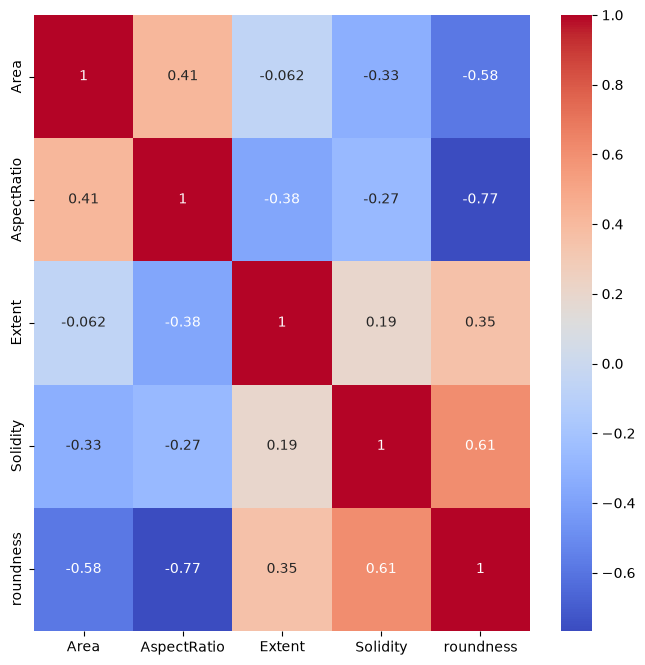

In [2]:
# Due to the multicollinearity described above,
# we'll keep Area and AspectRatio and drop the others:

X = drop_col(X, "Perimeter")
X = drop_col(X, "ConvexArea")
X = drop_col(X, "EquivDiameter")
X = drop_col(X, "Eccentricity")
X = drop_col(X, "Compactness")

# Making another heatmap to check results:
heatmp(X, 8, 8)
# None of these values are bove 0.9 or below -0.9
# (except each column with itself), so extreme multicollinearity
# has been removed.

# This concludes pre-processing.

## Question 1

### Feature Selection

I dropped the features that I did because either A) they had multicollinearity with other features, or B) the ReadMe for the dataset didn't explain what they were. I call out these instances in the code comments in the above sections. Since this dataset had a lot of columns originally, narrowing it down to 5 columns for the X dataframe seems like a solid turn of events. This should help ensure the analysis has multiple dimensions to work with without being too overburdened. Having too many columns can increase processing time and cause models to overfit to training data.

The remaining features are seen in the heatmap directly above this cell. They aren't TOO heavily correlated with each other (above 0.9 or below -0.9), so they should be good independent predictors. I don't know very much about beans or how this data was retrieved besides the basic explanation on the website containing the dataset, so the decision of which correlated columns to keep vs drop was somewhat arbitrary, but someone more familiar with the data could probably have a more nuanced approach.

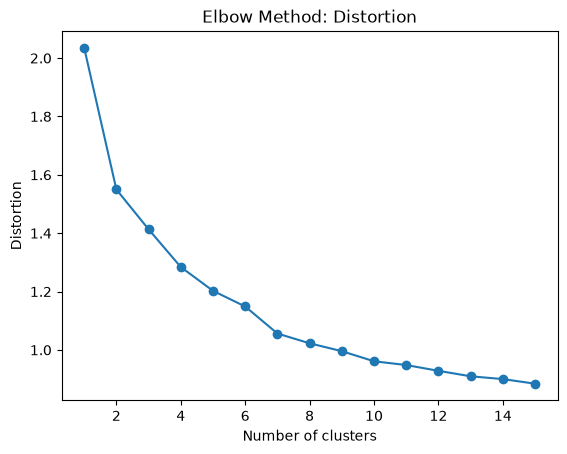

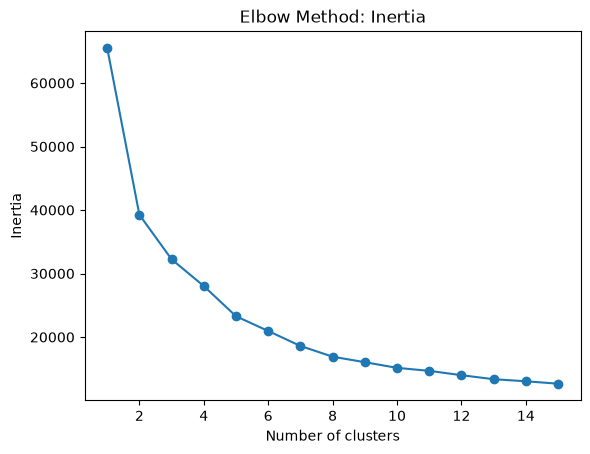

In [3]:
# K MEANS CLUSTERING
# This code used the class example as a starting point,
# and was made into a function where the inputs could
# be varied.

def k_means_cluster (input: pd.DataFrame, rdm:int, min:int, max:int):
    """
    This function creates and plots clusters for KMeans
    showing distortion and inertia.

    Input: pd dataframe (df), random state (rdm),
    minimum clusters (min), max clusters (max).

    Returns: Two plots showing elbow curves for
    distortion and intertia.
    """
    # Makes empty lists for use later.
    inertias = []
    distortions = []

    # Allows the min/max clusters to be input.
    for k in range(min, max+1):
        # Create & train KMeans model using k clusters
        model = KMeans(n_clusters=k, random_state=rdm).fit(input)

        # calculate euclidean distance between each point and
        # cluster center.
        distance = cdist(X, model.cluster_centers_, 'euclidean')
        # finds the distance from each point to the nearest cluster
        # center, then averages across all points
        distortion = sum(np.min(distance, axis=1))/input.shape[0]
        # adds distortion value for k clusters
        distortions.append(distortion)

        # calculates inertia by summing squared distance between
        # each point and its cluster center
        inertia = model.inertia_
        # adds inertia value for k clusters
        inertias.append(inertia)

    # plotting distortions
    plt.plot(range(min, max+1), distortions, marker='o')
    plt.title('Elbow Method: Distortion')
    plt.xlabel('Number of clusters')
    plt.ylabel('Distortion')
    plt.show()
    # plotting inertia
    plt.plot(range(min, max+1), inertias, marker='o')
    plt.title('Elbow Method: Inertia')
    plt.xlabel('Number of clusters')
    plt.ylabel('Inertia')
    return plt.show()

k_means_cluster(X, 10, 1, 15)


## Question 2

### Should you look at all of the data?

My main question of interest is whether the number of clusters will correspond to the number of classes. To answer this, I decided to look at all of the data, rather than a subset. This will help ensure I capture more of the variety between classes and inside classes of beans.

I removed some outliers in the preprocessing stage, so we're not looking at ALL the data, although an argument could be made that keeping in that natural variation would help my analysis further. In this case, I chose to remove some outliers mostly just to show that I could do it for the assignment.

### What is the ideal number of clusters? What approach did you use to find the ideal number and why?

Looking at the above plots, I would say the ideal number of clusters is about 5. The approach to take when looking at these plots is to try to find the "crook" of the elbow. In these charts, it's not super clear where that is, and you could honestly argue it's anywhere between 4 and 8 or so. But my eye says 5 is the point where we start to get diminishing returns across both graphs. I took this approach because it's what I learned in class and it's what online articles suggested.

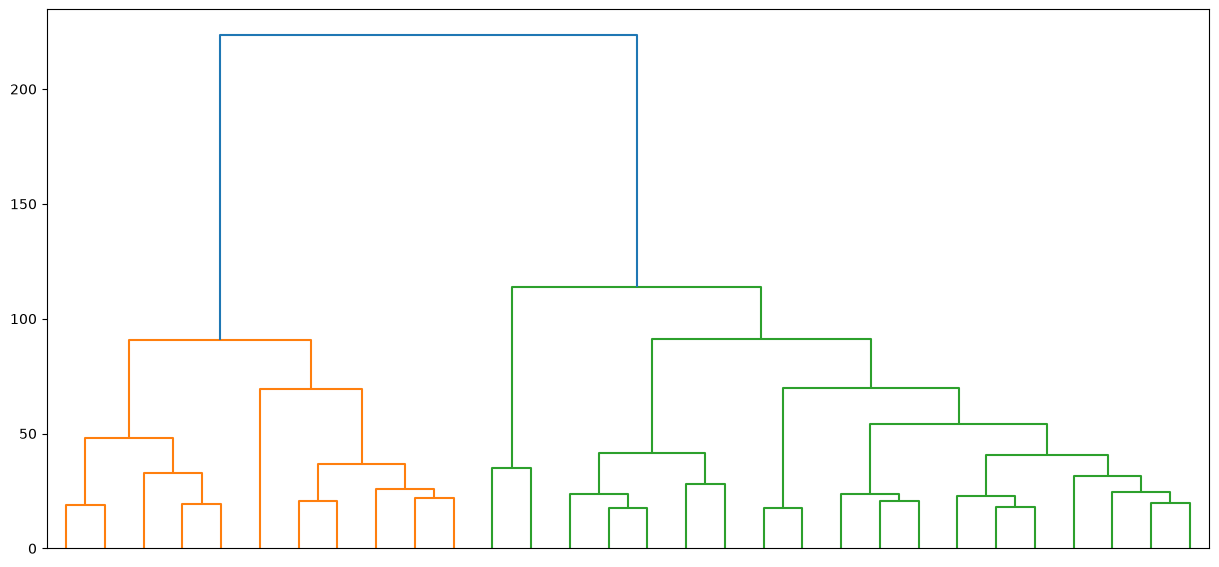

In [4]:
# HIERARCHICAL CLUSTERING

def hierarchical (df: pd.DataFrame, trun: int):
    """
    Performs hierarchical clustering.

    Input: dataframe of X values (df) and the number of
    clusters at which to truncate the plot (trun).

    Returns: dendrogram showing hierarchical clusters.
    """
    linked = linkage(df, 'ward')
    plt.figure(figsize=(15, 7))

    dendrogram(linked, no_labels=True, truncate_mode="lastp", p=trun, show_leaf_counts=True)

    return plt.show()

hierarchical(X, 30)

Predicted Cluster     1     2     3     4    5    6     7
Actual Class                                             
BARBUNYA             38     0    18     3  292    6   965
BOMBAY                0     0     0     0    0    0    22
CALI                 12     0    10    23   58   30  1497
DERMASON           1740    94  1670     2   34    2     4
HOROZ                75     0    19  1000  172  626    36
SEKER                81  1540   370     0   15    0    21
SIRA               1151     6  1362    29   12   14    62


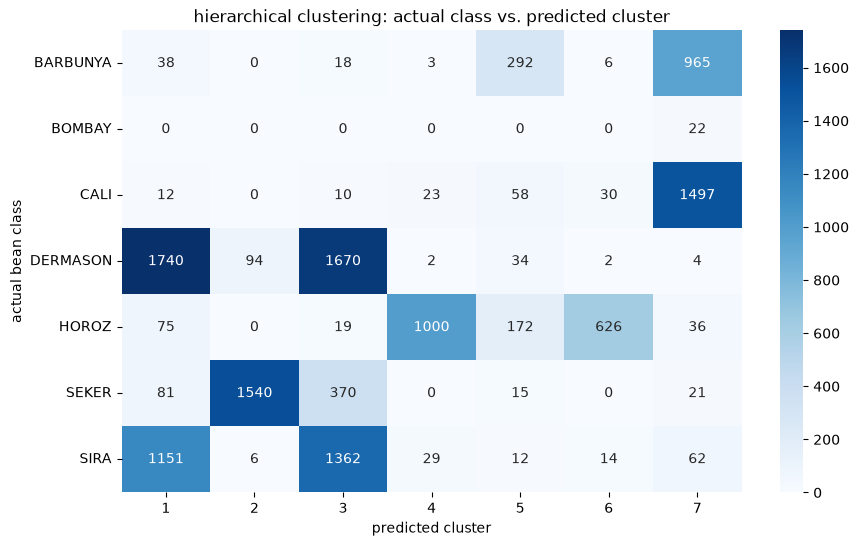

In [5]:
# Though it wasn't necessarily required, I wanted to
# answer the question: if we used 7 clusters, would
# they be mostly separated by class? This function
# helps to answer that question. The short answer is
# not really, the long answer is discussed in the
# markdown cells below. Gen AI was used to determine
# a starting approach here, and how to use the fcluster
# and crosstab functions to this effect.

def hierarchical_comparison(inp: pd.DataFrame, cls: pd.Series, c: int):
    """
    Shows a table and heatmap displaying which bean classes got put
    into which clusters to determine if it's a significant factor.

    Input: dataframe of X values (inp), series of class labels (cls),
    number of clusters to test (c).

    Returns: table and heatmap showing how many rows of each
    bean class were put into which cluster.
    """

    # perform hierarchical clustering
    linked = linkage(inp, method="ward")

    # divide the observations into c clusters
    cluster_labels = fcluster(
        linked,
        t=c,
        criterion="maxclust"
    )

    # create a dataframe containing actual classes and predicted clusters
    cluster_comparison = pd.DataFrame({
        "Actual Class": cls.to_numpy(),
        "Predicted Cluster": cluster_labels
    })

    # create a comparison table showing the number of observations
    # from each actual class assigned to each predicted cluster
    comparison_table = pd.crosstab(
        cluster_comparison["Actual Class"],
        cluster_comparison["Predicted Cluster"]
    )

    # display the comparison table
    print(comparison_table)

    # create a heatmap to visualize the clustering results
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        comparison_table,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("hierarchical clustering: actual class vs. predicted cluster")
    plt.xlabel("predicted cluster")
    plt.ylabel("actual bean class")

    plt.show()


# run hierarchical clustering comparison
hierarchical_comparison(X, y, 7)

## Bean Class Cluster Heatmap

The heatmap above looks at how many rows of each bean class were placed into each cluster when we force the dataset into 7 clusters exactly. It looks like the CALI class is the most unique of the classes, since nearly all of its instances were placed into cluster #7. Same with Bombay, although it had very few instances to begin with.

The other bean classes are split between at least two decent-sized clusters, with Dermason and Sira being the most evenly split. This indicates that while differences between some classes are significant, differences within classes are also significant. Therefore, going with the obvious answer of 7 clusters for 7 classes of beans is not necessarily correct here! As discussed in the answers to Questions 2 (above) and 3 (below), neither method suggested 7 clusters, so this checks out.

So, to answer my question of if the 7 bean classes would fit neatly into 7 clusters: no they do not, and 7 does not seem to be the ideal number of clusters.

## Question 3

## For hierarchical clustering: What is the ideal number of clusters? Which approach did you use to find the ideal number of clusters and why?

The dendrogram suggests 2 as the optimal number of clusters. The longest vertical line that isn't intersected by a horizontal line is the blue one on the right side, and if we draw an imaginary horizontal line through that, we end up with 2 intersections, meaning two clusters. Another way I saw online is taking the number of colors on the graph and subtracting one (3 - 1 = 2) to get the ideal number of clusters, as mentioned in the below video:

https://www.youtube.com/watch?v=4DInt3H2UNE

I used the vertical line approach because it's what we discussed in class and it was the main way of determining ideal clusters using hierarchical clustering that I saw online. 2 seems low for this dataset, but that seems to be what the dendrogram suggests.

## Question 4

### Compare the results of 2 and 3. Which approach do you think is best? Why?

Between 2 and 3, I think the K Means (elbow graphs) approach is best here. In this case, we already have a vague idea of the number of clusters, since we have 7 classes of beans. As discussed earlier, that doesn't mean it's exactly 7, but we can make an educated guess that it's probably not too much higher or lower. K Means is a good choice when you have a rough idea of k. For practical purposes, it's less computationally intensive, which makes a big difference in this dataset. On my machine, it took a few seconds to make the elbow plots, but it took several minutes to generate the dendrogram for the hierarchical clustering. Also, just looking at the results, 5 clusters from the elbow charts seems more acurate than only 2 from the dendrogram.

Article used for comparing these two approaches: https://www.geeksforgeeks.org/machine-learning/difference-between-k-means-and-hierarchical-clustering/

### What does this unsupervised learning activity teach you about the data you're exploring?

It teaches me that there are more differences WITHIN some bean classes than between them. I'd thought that the 7 classes would line up neatly into 7 clusters, but as discussed above, they don't. Going into an analysis with bias can be dangerous! When looking at the elbow graphs at first, I reaaaally tried to make 7 work, but that just isn't how things turned out.

It also teaches me that having an understanding of the kinda of data you're working with can be useful. I don't know anything about beans, so I'm not sure what makes some classes have more differences within than with other classes. But a bean expert might have some ideas for other analyses I could perform. Maybe some box plots of different characteristics by class could sort some of that out.

## Linting:

This code got a linting score of 93.9%, as seen below:

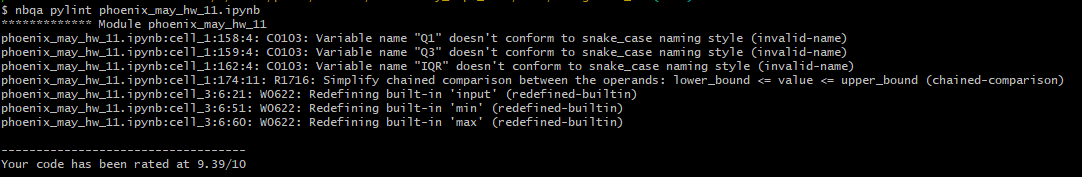